In [ ]:
# JERICHON import bootstrap (shared resolver in src/project_paths.py)
from pathlib import Path
import os, sys

# Locate repository from the current working directory or its parents.
_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
for _base in list(_candidates):
    try:
        _candidates.extend(_child for _child in _base.iterdir() if _child.is_dir())
    except (OSError, PermissionError):
        pass
PROJECT_ROOT = next((p.resolve() for p in _candidates
                     if (p / "src" / "__init__.py").is_file()
                     and (p / "src" / "data" / "builders").is_dir()), None)
if PROJECT_ROOT is None:
    _env_root = os.environ.get("JERICHON_PROJECT_ROOT")
    if _env_root:
        _candidate = Path(_env_root).expanduser().resolve()
        if (_candidate / "src" / "__init__.py").is_file():
            PROJECT_ROOT = _candidate
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Не найден корень JERICHON. Откройте VS Code в папке репозитория "
        "или задайте JERICHON_PROJECT_ROOT.")
if str(PROJECT_ROOT) in sys.path:
    sys.path.remove(str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT))
from src.project_paths import bootstrap_project, find_project_root
PROJECT_ROOT = bootstrap_project(PROJECT_ROOT)


# JERICHON — Research 01: data quality → first baseline

**Работаем только с уже скачанной историей.** Этот notebook не обращается к AlgoPack API и не архивирует/перезаписывает исходные данные.

Порядок:
1. Загрузить локальные `trades` и Super Candles за все сохранённые даты.
2. Построить Dollar Bars и 474 причинно корректных признака через подготовленный `jerichon_feature_pipeline.py`.
3. Проверить `NaN`, `±inf`, нулевые/константные признаки, дубликаты и temporal provenance.
4. Подготовить отдельную копию матрицы для ML.
5. Построить бинарную цель UP/DOWN, исключить TIME из обучения и запустить Optuna на полной матрице 474 признака с пересборкой датасета в каждом trial.

Нули сами по себе не считаются аномалией: в неликвидное время они могут быть нормальными. Мы измеряем их долю, но не удаляем строки только из-за нулей.

**Ожидаемый контракт:** 474 ML-признака; `bar_ts` и provenance не входят в `X`.

In [16]:
# 0. CONFIG + IMPORTS
from pathlib import Path
import sys, inspect, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplcyberpunk
plt.style.use('cyberpunk')
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix)

TICKER = "SMLT"                  # поменяй тикер при необходимости
DOLLAR_THRESHOLD = 10_000_000   # порог из reference notebook jerichon_mark_63(3)
MSK = "Europe/Moscow"
# Historical labels: CUSUM events + Triple Barrier (not fixed-horizon return labels).
CUSUM_THRESHOLD = 0.001
PT_SL = (2.4, 1.5)              # (take-profit multiplier, stop-loss multiplier); intentionally asymmetric
VERTICAL_HORIZON = 50           # vertical barrier in Dollar Bars
TARGET_WINDOW = 55              # volatility estimate window for Triple Barrier
EXPECTED_FEATURES = 474

# Автоматически ищем корень репозитория JERICHON, не фиксируем путь конкретного пользователя.
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for p in candidates:
        if (p / "data" / "for_ml" / "storage" / "history").exists() and (p / "src" / "data" / "builders").exists():
            return p
    raise FileNotFoundError(
        "Не найден корень JERICHON. Открой notebook из папки репозитория "
        "или укажи PROJECT_ROOT вручную."
    )

ROOT = PROJECT_ROOT / "data"
if str(ROOT.parent) not in sys.path:
    sys.path.insert(0, str(ROOT.parent))
HISTORY_ROOT = ROOT / "for_ml" / "storage" / "history"

from src.data.builders.dollar_bars import InformationDrivenBars
from src.data.builders.micro_features import MicroFeatures
from src.data.builders.build_features import FeatureBuilder
from src.data.builders import jerichon_feature_pipeline as jfp
from src.backtesting.backtest_engine import (backtest_saved_catboost, BacktestConfig,)

print("Ticker       :", TICKER)
print("Pipeline     :", Path(inspect.getfile(jfp)).resolve())
print("Pipeline API :", [n for n in ("build_feature_dataset", "build_dollar_bars_from_trades", "_base", "_build_sc_features", "_choose_availability", "_attach_source") if hasattr(jfp, n)])

Ticker       : SMLT
Pipeline     : C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py
Pipeline API : ['build_feature_dataset', 'build_dollar_bars_from_trades', '_base', '_build_sc_features', '_choose_availability', '_attach_source']


## 1. Загрузка локальной истории

Формат путей сохранён **как в `jerichon_mark_63(3).ipynb`**:

- `data/for_ml/storage/history/realtime/{TICKER}/{YYYY-MM-DD}/trades.parquet`
- `data/for_ml/storage/history/supercandles/{TICKER}/{YYYY-MM-DD}/{tradestats,obstats,orderstats}.parquet`

Файлы только читаются. Если какой-то источник отсутствует, notebook покажет это явно.

In [17]:
def available_dates(history_root, ticker):
    dates = set()
    for kind in ("realtime", "supercandles"):
        p = history_root / kind / ticker
        if p.exists():
            dates.update(x.name for x in p.iterdir() if x.is_dir())
    return sorted(d for d in dates if len(d) == 10 and d[4] == "-" and d[7] == "-")

def load_local_history(history_root, ticker):
    keys = ("candles", "trades", "orderbook", "tradestats", "obstats", "orderstats")
    frames = {k: [] for k in keys}
    dates = available_dates(history_root, ticker)

    if not dates:
        raise FileNotFoundError(f"Для {ticker} не найдены сохранённые даты в {history_root}")

    for day in dates:
        for key in ("candles", "trades", "orderbook"):
            p = history_root / "realtime" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING: не удалось прочитать {p}: {e}")

        for key in ("tradestats", "obstats", "orderstats"):
            p = history_root / "supercandles" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING: не удалось прочитать {p}: {e}")

    out = {k: (pd.concat(v, ignore_index=True) if v else pd.DataFrame()) for k, v in frames.items()}
    print(f"Saved dates discovered: {len(dates)}")
    print(f"Date range            : {dates[0]} → {dates[-1]}")
    print("\\nLocal rows:")
    display(pd.DataFrame({"source": list(out), "rows": [len(out[k]) for k in out]}))
    missing = [s for s in ("trades", "tradestats", "obstats", "orderstats") if out[s].empty]
    if missing:
        raise RuntimeError(f"Не хватает локальных источников: {missing}. API-запрос не будет выполняться.")
    return out, dates

data, SAVED_DATES = load_local_history(HISTORY_ROOT, TICKER)

Saved dates discovered: 26
Date range            : 2026-08-28 → 2026-10-09
\nLocal rows:


,source,rows
0,candles,23336
1,trades,2021772
2,orderbook,520
3,tradestats,4688
4,obstats,4573
5,orderstats,4723


## 2. Построение Dollar Bars и 474 признаков

Используем подготовленный модуль `jerichon_feature_pipeline.py`, а не копируем его инженерный код в notebook. Важно: **не вызываем** публичный `build_feature_dataset()`, если он сам создаёт `AlgoPackProvider`; вместо этого вызываем локальные функции модуля над уже прочитанными DataFrame.

Если локальная версия модуля не содержит ожидаемые helper-функции, выполнение остановится с понятной ошибкой, а не отправит запрос в API.

In [18]:
# Сначала проверяем интерфейс установленного файла — никаких сетевых вызовов здесь нет.
required_helpers = (
    "_trades_for_bars",
    "build_dollar_bars_from_trades",
    "_base",
    "_build_sc_features",
    "_choose_availability",
    "_attach_source",
)
missing_helpers = [name for name in required_helpers if not hasattr(jfp, name)]
if missing_helpers:
    raise RuntimeError(
        "В установленном jerichon_feature_pipeline.py не найдены helper-функции: "
        f"{missing_helpers}. Проверь, что в проекте стоит актуальная версия pipeline. "
        "Этот notebook намеренно не переключается на API."
    )

print("Helper signatures:")
for name in required_helpers:
    print(f"  {name}{inspect.signature(getattr(jfp, name))}")

Helper signatures:
  _trades_for_bars(trades)
  build_dollar_bars_from_trades(trades, threshold=13000000)
  _base(bars)
  _build_sc_features(raw_sources, bars_for_features)
  _choose_availability(df, source_name)
  _attach_source(bars, feature_frame, raw_source, source)


In [19]:
# Dollar Bars: используем тот же денежный объём VALUE / PRICE, что и в reference.
bars = jfp.build_dollar_bars_from_trades(data["trades"], threshold=DOLLAR_THRESHOLD)
if bars is None or bars.empty:
    raise RuntimeError("Dollar Bar builder вернул пустой результат.")

# Унифицируем имя времени для последующих causal joins.
if "bar_ts" not in bars.columns:
    if "close_time" not in bars.columns:
        raise RuntimeError(f"В bars нет bar_ts/close_time. Колонки: {list(bars.columns)}")
    bars["bar_ts"] = pd.to_datetime(bars["close_time"], errors="coerce", utc=True)
else:
    bars["bar_ts"] = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)

bars = (bars.dropna(subset=["bar_ts"])
             .sort_values("bar_ts")
             .drop_duplicates("bar_ts", keep="last")
             .reset_index(drop=True))

print("Dollar Bars:", len(bars))
print("Period:", bars["bar_ts"].min(), "→", bars["bar_ts"].max())
display(bars.head(3))

Dollar Bars: 8892
Period: 2026-08-28 04:02:33+00:00 → 2026-10-09 17:44:08+00:00


,open,high,low,close,volume,value,count,open_time,close_time,bar_ts
0,357.8,358.0,356.4,356.8,28423.0,10159440.4,204,2026-08-28 03:59:48+00:00,2026-08-28 04:02:33+00:00,2026-08-28 04:02:33+00:00
1,356.8,356.8,354.6,355.0,28531.0,10143107.0,217,2026-08-28 04:02:33+00:00,2026-08-28 04:04:39+00:00,2026-08-28 04:04:39+00:00
2,355.0,356.4,354.6,356.4,28577.0,10163407.0,259,2026-08-28 04:04:39+00:00,2026-08-28 04:09:31+00:00,2026-08-28 04:09:31+00:00


In [20]:
# Base 73 + Super Candle 401. Работаем через helper-функции pipeline.
base_raw = jfp._base(bars.copy())
if isinstance(base_raw, tuple):
    # Поддержка версий helper, возвращающих (features, metadata).
    base_raw = base_raw[0]
if not isinstance(base_raw, pd.DataFrame):
    raise TypeError(f"_base должен вернуть DataFrame, получено: {type(base_raw)}")

# Приводим base frame к контракту bar_ts + 73 числовых признака.
if "bar_ts" not in base_raw.columns:
    if "close_time" in base_raw.columns:
        base_raw = base_raw.rename(columns={"close_time": "bar_ts"})
    elif isinstance(base_raw.index, pd.DatetimeIndex):
        base_raw = base_raw.reset_index().rename(columns={base_raw.index.name or "index": "bar_ts"})
    elif "ts" in base_raw.columns:
        base_raw = base_raw.rename(columns={"ts": "bar_ts"})
    else:
        raise RuntimeError(f"Не найден временной ключ в _base output. Колонки: {list(base_raw.columns)[:25]}")

base_raw["bar_ts"] = pd.to_datetime(base_raw["bar_ts"], errors="coerce", utc=True)
base_raw = base_raw.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)

# _build_sc_features может возвращать feature_frames либо (feature_frames, groups).
# Адаптируем Dollar Bars к формату, ожидаемому pipeline.
bars_for_sc = bars.copy()

# В pipeline ожидаются ts и CLOSE.
if "ts" not in bars_for_sc.columns:
    if "bar_ts" in bars_for_sc.columns:
        bars_for_sc["ts"] = bars_for_sc["bar_ts"]
    elif "close_time" in bars_for_sc.columns:
        bars_for_sc["ts"] = bars_for_sc["close_time"]
    else:
        raise KeyError("В bars отсутствует временная колонка ts/bar_ts/close_time")

if "CLOSE" not in bars_for_sc.columns:
    if "close" in bars_for_sc.columns:
        bars_for_sc["CLOSE"] = bars_for_sc["close"]
    else:
        raise KeyError("В bars отсутствует цена закрытия CLOSE/close")

bars_for_sc["ts"] = pd.to_datetime(bars_for_sc["ts"], errors="coerce", utc=True)

bars_for_sc = (
    bars_for_sc.dropna(subset=["ts"])
    .sort_values("ts")
    .reset_index(drop=True))

sc_result = jfp._build_sc_features(data, bars_for_sc)

if isinstance(sc_result, tuple):
    feature_frames = sc_result[0]
    feature_groups = sc_result[1] if len(sc_result) > 1 else {}
else:
    feature_frames = sc_result
    feature_groups = {}

if not isinstance(feature_frames, dict):
    raise TypeError("_build_sc_features должен возвращать dict feature frames.")

print("Base output shape:", base_raw.shape)
print("Super Candle feature groups:", list(feature_frames))

Base output shape: (8892, 74)
Super Candle feature groups: ['tradestats', 'orderstats', 'obstats']


In [21]:
# Availability validation and causal joins, source by source.
# Helpers' outputs are inspected to support the current prepared module contract.
validated = {}
availability_diagnostics = []

for source in ("tradestats", "obstats", "orderstats"):
    if data[source].empty:
        raise RuntimeError(f"Локальный источник {source} пуст.")

    result = jfp._choose_availability(data[source].copy(), source)
    if isinstance(result, tuple):
        validated[source] = result[0]
        if len(result) > 1 and isinstance(result[1], pd.DataFrame):
            availability_diagnostics.append(result[1])
    else:
        validated[source] = result

print("Validated sources:")
for source, frame in validated.items():
    print(f"  {source:12s}: {len(frame):,} rows, columns={len(frame.columns)}")

if availability_diagnostics:
    display(pd.concat(availability_diagnostics, ignore_index=True))

Validated sources:
  tradestats  : 4,688 rows, columns=2
  obstats     : 4,573 rows, columns=2
  orderstats  : 4,723 rows, columns=2


In [22]:
# Normalize the bars frame for the pipeline's attach helper.
bar_frame = bars.copy()
if "bar_ts" not in bar_frame.columns:
    raise RuntimeError("bar_ts missing from Dollar Bars.")

# Resolve each raw source to the corresponding feature frame by name.
def resolve_feature_frame(source, frames):
    if source in frames:
        return frames[source]
    matches = [k for k in frames if source.lower() in str(k).lower()]
    if len(matches) == 1:
        return frames[matches[0]]
    raise RuntimeError(f"Не удалось однозначно сопоставить {source} с feature frame. Доступны: {list(frames)}")

causal = bar_frame.copy()
for source in ("tradestats", "obstats", "orderstats"):
    feature_frame = resolve_feature_frame(source, feature_frames)
    
    # ИСПРАВЛЕНО: правильный порядок аргументов + исходные данные вместо validated
    attached = jfp._attach_source(causal, feature_frame, data[source], source)
    
    # Поддержка helper, возвращающего либо изменённый frame, либо None in-place.
    if isinstance(attached, pd.DataFrame):
        causal = attached
    print(f"{source:12s} attached → {causal.shape}")

# Добавляем base features по точному bar_ts.
base_cols = [c for c in base_raw.columns if c != "bar_ts" and pd.api.types.is_numeric_dtype(base_raw[c])]
if len(base_cols) != 73:
    raise RuntimeError(f"Ожидалось 73 base features, найдено {len(base_cols)}.")

base_join = base_raw[["bar_ts"] + base_cols].copy()
base_join = base_join.rename(columns={c: f"base__{c}" for c in base_cols})
base_cols = [c for c in base_join.columns if c.startswith("base__")]

if "bar_ts" not in causal.columns:
    raise RuntimeError(f"После causal join нет bar_ts. Колонки: {list(causal.columns)[:30]}")

causal["bar_ts"] = pd.to_datetime(causal["bar_ts"], errors="coerce", utc=True)
base_join["bar_ts"] = pd.to_datetime(base_join["bar_ts"], errors="coerce", utc=True)
causal = causal.merge(base_join, on="bar_ts", how="left", validate="one_to_one")

# Identify features and provenance without admitting timestamps into X.
time_cols = {"bar_ts", "bar_ts_utc", "ts", "ts_utc", "close_time"}
provenance_cols = [
    c for c in causal.columns
    if c.endswith("__event_ts") or c.endswith("__available_at")
]
sc_prefixes = ("tradestats__", "obstats__", "orderstats__")
sc_feature_cols = [
    c for c in causal.columns
    if c.startswith(sc_prefixes)
    and c not in provenance_cols
    and pd.api.types.is_numeric_dtype(causal[c])
]
# Не включаем сырые OHLCV/служебные колонки из bars: только канонические 73 + 401.
feature_cols = base_cols + sc_feature_cols

if len(feature_cols) != EXPECTED_FEATURES:
    raise RuntimeError(
        f"Feature inventory mismatch: {len(feature_cols)} numeric ML features, expected {EXPECTED_FEATURES}. "
        "Не продолжаем обучение на непроверенной матрице."
    )

if len(feature_cols) != len(set(feature_cols)):
    raise RuntimeError("Есть дублирующиеся имена признаков.")

FINAL_DATASET = causal[["bar_ts"] + feature_cols + provenance_cols].copy()
FINAL_DATASET = FINAL_DATASET.sort_values("bar_ts").reset_index(drop=True)
X_raw = FINAL_DATASET[feature_cols].copy()

print("FINAL_DATASET:", FINAL_DATASET.shape)
print("Rows:", len(FINAL_DATASET))
print("ML features:", len(feature_cols))
print("Provenance columns:", len(provenance_cols))

tradestats   attached → (8892, 106)
obstats      attached → (8892, 244)
orderstats   attached → (8892, 417)
FINAL_DATASET: (8892, 481)
Rows: 8892
ML features: 474
Provenance columns: 6


## 3. Temporal audit

Проверяем `available_at <= bar_ts` и `event_ts <= bar_ts` для каждого источника. Признаки из будущего — блокирующая ошибка. Дубликаты/пропуски/бесконечности дальше рассматриваются отдельно.

In [23]:
temporal_rows = []
for source in ("tradestats", "obstats", "orderstats"):
    av_col = f"{source}__available_at"
    ev_col = f"{source}__event_ts"
    if av_col not in FINAL_DATASET.columns or ev_col not in FINAL_DATASET.columns:
        raise RuntimeError(f"Нет provenance для {source}: ожидались {av_col}, {ev_col}")

    av = pd.to_datetime(FINAL_DATASET[av_col], errors="coerce", utc=True)
    ev = pd.to_datetime(FINAL_DATASET[ev_col], errors="coerce", utc=True)
    bar_ts = pd.to_datetime(FINAL_DATASET["bar_ts"], errors="coerce", utc=True)

    bad_av = av.notna() & (av > bar_ts)
    bad_ev = ev.notna() & (ev > bar_ts)
    temporal_rows.append({
        "source": source,
        "bars": len(FINAL_DATASET),
        "availability_future_violations": int(bad_av.sum()),
        "event_future_violations": int(bad_ev.sum()),
        "availability_missing_pct": round(float(av.isna().mean() * 100), 3),
        "event_missing_pct": round(float(ev.isna().mean() * 100), 3),
    })

temporal_audit = pd.DataFrame(temporal_rows)
display(temporal_audit)

if temporal_audit[["availability_future_violations", "event_future_violations"]].to_numpy().sum() != 0:
    raise RuntimeError("TEMPORAL AUDIT FAILED: обнаружен look-ahead по provenance.")
print("TEMPORAL AUDIT: PASS")

,source,bars,availability_future_violations,event_future_violations,availability_missing_pct,event_missing_pct
0,tradestats,8892,0,0,1.046,1.046
1,obstats,8892,0,0,1.080,1.080
2,orderstats,8892,0,0,1.035,1.035


TEMPORAL AUDIT: PASS


## 4. Проверка качества признаков

Нулевые значения не удаляем автоматически. Важные показатели:
- `NaN` и `±inf` по каждому признаку;
- доля нулей (диагностика, не критерий удаления);
- константные признаки;
- полностью пустые признаки;
- дублирующиеся строки и timestamps.

Исходный `FINAL_DATASET` не перезаписывается. Для модели создаётся отдельная копия, в которой бесконечности переводятся в `NaN`; далее imputer обучается только на train.

In [24]:
X_num = X_raw.apply(pd.to_numeric, errors="coerce")
arr = X_num.to_numpy(dtype="float64", copy=True)
finite_mask = np.isfinite(arr)

quality = pd.DataFrame(index=X_num.columns)
quality["missing_pct"] = X_num.isna().mean() * 100
quality["positive_inf"] = np.isposinf(arr).sum(axis=0)
quality["negative_inf"] = np.isneginf(arr).sum(axis=0)
quality["zero_pct"] = (X_num.eq(0).mean() * 100)
quality["unique_values"] = X_num.nunique(dropna=True)
quality["all_missing"] = X_num.isna().all()
quality["constant_or_single_value"] = quality["unique_values"] <= 1
quality["non_finite_total"] = quality["positive_inf"] + quality["negative_inf"]

print("Rows:", len(X_num), "| features:", X_num.shape[1])
print("NaN cells:", int(X_num.isna().sum().sum()))
print("+inf cells:", int(np.isposinf(arr).sum()))
print("-inf cells:", int(np.isneginf(arr).sum()))
print("Zero cells (% of all feature cells):", round(float(X_num.eq(0).to_numpy().mean() * 100), 2))
print("Duplicate bar_ts:", int(FINAL_DATASET["bar_ts"].duplicated().sum()))
print("Duplicate feature rows:", int(X_num.duplicated().sum()))

print("\\nWorst missingness:")
display(quality.sort_values(["missing_pct", "non_finite_total"], ascending=False).head(30))

print("\\nFeatures with infinities:")
display(quality.loc[quality["non_finite_total"] > 0].sort_values("non_finite_total", ascending=False))

print("\\nConstant / all-missing features:")
display(quality.loc[quality["constant_or_single_value"] | quality["all_missing"]])

Rows: 8892 | features: 474
NaN cells: 41457
+inf cells: 0
-inf cells: 0
Zero cells (% of all feature cells): 0.86
Duplicate bar_ts: 0
Duplicate feature rows: 0
\nWorst missingness:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total
tradestats__ts_flow_x_return_ret,14.799820,0,0,0.000000,1806,False,False,0
tradestats__ts_vwap_b_s_bps_ret,9.446694,0,0,1.405758,1993,False,False,0
tradestats__ts_trade_imbalance_ret,3.160144,0,0,0.000000,2483,False,False,0
obstats__ob_vol_imb_bbo_vs_deep_ret,2.530364,0,0,0.461089,1699,False,False,0
obstats__ob_val_imb_bbo_vs_deep_ret,2.316689,0,0,0.798471,1757,False,False,0
orderstats__os_put_vwap_b_s_bps_ret,1.383266,0,0,0.000000,2521,False,False,0
obstats__ob_1mio_liquidity_cost_bps_ret,1.315789,0,0,1.158345,2397,False,False,0
orderstats__os_put_orders_imb_ret,1.315789,0,0,0.000000,2538,False,False,0
tradestats__ts_vwap_b_s_bps_z3,1.293297,0,0,0.348628,2493,False,False,0
tradestats__ts_vwap_b_s_bps_ma3,1.293297,0,0,0.033738,2473,False,False,0


\nFeatures with infinities:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total


\nConstant / all-missing features:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total


In [25]:
# Separate ML copy: keep source dataset unchanged.
X_model = X_num.replace([np.inf, -np.inf], np.nan).copy()

# Remove only features that cannot carry information at all (all missing or constant).
drop_features = quality.index[quality["all_missing"] | quality["constant_or_single_value"]].tolist()
if drop_features:
    print("Removing non-informative columns from model copy:", len(drop_features))
    print(drop_features[:30])
    X_model = X_model.drop(columns=drop_features)

print("X_model shape:", X_model.shape)
print("Remaining NaN cells (to be handled by train-only imputer):", int(X_model.isna().sum().sum()))

# Optional strict stop for pathological data; does not delete rows.
if X_model.shape[1] == 0:
    raise RuntimeError("После удаления пустых/константных признаков не осталось признаков.")

X_model shape: (8892, 474)
Remaining NaN cells (to be handled by train-only imputer): 41457


## 5. CUSUM + Triple Barrier: бинарная цель UP/DOWN

Triple Barrier по-прежнему строит три исходные метки, чтобы диагностировать распределение событий:
- `+1` — первым достигнут верхний барьер (`UP`);
- `-1` — первым достигнут нижний барьер (`DOWN`);
- `0` — до вертикального барьера не достигнут ни один горизонтальный барьер (`TIME`).

**В модель `TIME` не попадает вообще.** После визуализации распределения остаются только события `UP` и `DOWN`, а целевая переменная кодируется как `DOWN=0`, `UP=1`. Train/holdout делятся хронологически, пересекающие границу исходы purged.

CUSUM + TRIPLE BARRIER
CUSUM threshold : 0.001
PT_SL           : (2.4, 1.5) (TP multiplier, SL multiplier)
Vertical horizon: 50 Dollar Bars
Target window   : 55
CUSUM events    : 5,928
Triple Barrier events: 5,927
Raw labels: -1=DOWN, 0=TIME, +1=UP
  DOWN :   3,698 ( 62.39%)
  TIME :      23 (  0.39%)
  UP   :   2,206 ( 37.22%)


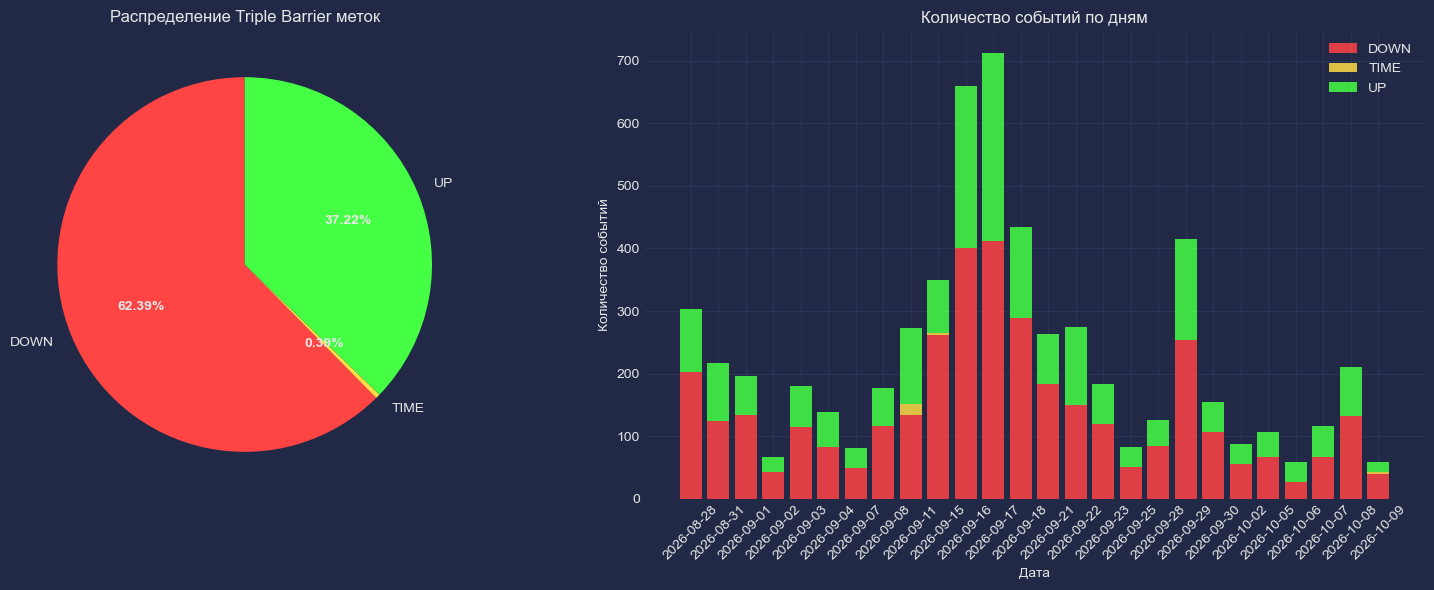


Aligned events before excluding TIME: 5,927
label
-1    3698
 0      23
 1    2206
Name: count, dtype: int64


In [26]:
# =============================================================================
# LABELS: CUSUM → TRIPLE BARRIER → EVENT-ALIGNED X/y → BINARY TARGET
# =============================================================================
from src.data.labeling.cusum import cusum_filter
from src.data.labeling.triple_barrier import triple_barrier_labeling

# Use exactly the Dollar Bars that produced FINAL_DATASET.
bars_for_labeling = bars.copy()
if "bar_ts" not in bars_for_labeling.columns:
    raise RuntimeError(f"В bars отсутствует bar_ts. Колонки: {list(bars_for_labeling.columns)}")

rename_map = {
    "open": "OPEN", "high": "HIGH", "low": "LOW", "close": "CLOSE",
    "OPEN": "OPEN", "HIGH": "HIGH", "LOW": "LOW", "CLOSE": "CLOSE",
}
bars_for_labeling = bars_for_labeling.rename(columns=rename_map)
required_ohlc = ["HIGH", "LOW", "CLOSE"]
missing_ohlc = [c for c in required_ohlc if c not in bars_for_labeling.columns]
if missing_ohlc:
    raise RuntimeError(f"Для Triple Barrier не хватает OHLC-колонок: {missing_ohlc}")

bars_for_labeling["bar_ts"] = pd.to_datetime(
    bars_for_labeling["bar_ts"], errors="coerce", utc=True
)
bars_for_labeling = (
    bars_for_labeling.dropna(subset=["bar_ts"] + required_ohlc)
    .sort_values("bar_ts")
    .drop_duplicates("bar_ts", keep="last")
    .set_index("bar_ts")
)
bars_for_labeling.index.name = "bar_ts"

events_idx = cusum_filter(
    bars_for_labeling["CLOSE"].astype(float),
    threshold=CUSUM_THRESHOLD,
)
events_idx = pd.DatetimeIndex(events_idx)
events_idx = events_idx[events_idx.isin(bars_for_labeling.index)]
events_idx = events_idx.drop_duplicates().sort_values()

print("=" * 80)
print("CUSUM + TRIPLE BARRIER")
print("=" * 80)
print(f"CUSUM threshold : {CUSUM_THRESHOLD}")
print(f"PT_SL           : {PT_SL} (TP multiplier, SL multiplier)")
print(f"Vertical horizon: {VERTICAL_HORIZON} Dollar Bars")
print(f"Target window   : {TARGET_WINDOW}")
print(f"CUSUM events    : {len(events_idx):,}")
if len(events_idx) == 0:
    raise RuntimeError("CUSUM не нашёл событий. Проверь CUSUM_THRESHOLD и входные бары.")

labeled_all = triple_barrier_labeling(
    bars=bars_for_labeling,
    events=events_idx,
    pt_sl=PT_SL,
    vertical_barrier=VERTICAL_HORIZON,
    target_window=TARGET_WINDOW,
    target_method="ewm",
)
if labeled_all is None or labeled_all.empty:
    raise RuntimeError("Triple Barrier вернул пустую таблицу меток.")
if not {"label", "t1"}.issubset(labeled_all.columns):
    raise RuntimeError(
        "Ожидались колонки label и t1; получены: "
        f"{list(labeled_all.columns)}"
    )

labeled_all.index = pd.to_datetime(labeled_all.index, errors="coerce", utc=True)
labeled_all = labeled_all[~labeled_all.index.isna()].sort_index()
labeled_all = labeled_all[labeled_all["label"].isin([-1, 0, 1])].copy()
labeled_all["label"] = labeled_all["label"].astype(int)
labeled_all["t1"] = pd.to_datetime(labeled_all["t1"], errors="coerce", utc=True)

print(f"Triple Barrier events: {len(labeled_all):,}")
print("Raw labels: -1=DOWN, 0=TIME, +1=UP")
label_counts = labeled_all["label"].value_counts().reindex([-1, 0, 1], fill_value=0)
for value, name in [(-1, "DOWN"), (0, "TIME"), (1, "UP")]:
    count = int(label_counts.loc[value])
    pct = 100 * count / len(labeled_all) if len(labeled_all) else 0
    print(f"  {name:5s}: {count:7,d} ({pct:6.2f}%)")

# Visual diagnostics include TIME so we can see how often the vertical barrier wins.
label_names = {-1: "DOWN", 0: "TIME", 1: "UP"}
label_colors = {-1: "#ff4444", 0: "#ffdd44", 1: "#44ff44"}
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_counts = [int(label_counts.loc[v]) for v in (-1, 0, 1)]
if sum(plot_counts):
    _, _, autotexts = axes[0].pie(
        plot_counts,
        labels=[label_names[v] for v in (-1, 0, 1)],
        colors=[label_colors[v] for v in (-1, 0, 1)],
        autopct="%1.2f%%",
        startangle=90,
    )
    for t in autotexts:
        t.set_fontsize(10)
        t.set_fontweight("bold")
axes[0].set_title("Распределение Triple Barrier меток")

plot_labels = pd.DataFrame({
    "day": pd.DatetimeIndex(labeled_all.index).date,
    "label": labeled_all["label"].to_numpy(),
})
daily_counts = (
    plot_labels.groupby(["day", "label"]).size()
    .unstack(fill_value=0)
    .reindex(columns=[-1, 0, 1], fill_value=0)
    .sort_index()
)
bottom = np.zeros(len(daily_counts), dtype=float)
for cls in (-1, 0, 1):
    vals = daily_counts[cls].to_numpy()
    axes[1].bar(
        daily_counts.index.astype(str), vals, bottom=bottom,
        label=label_names[cls], color=label_colors[cls], alpha=0.85,
    )
    bottom += vals
axes[1].set_title("Количество событий по дням")
axes[1].set_xlabel("Дата")
axes[1].set_ylabel("Количество событий")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
plt.tight_layout()
plt.show()

# Event-aligned X/y. One concat avoids pandas' highly-fragmented DataFrame warning.
if len(FINAL_DATASET) != len(X_model):
    raise RuntimeError(
        f"FINAL_DATASET и X_model имеют разную длину: {len(FINAL_DATASET)} vs {len(X_model)}"
    )
model_feature_cols = list(X_model.columns)
feature_table = pd.concat(
    [FINAL_DATASET[["bar_ts"]].reset_index(drop=True),
     X_model.reset_index(drop=True)],
    axis=1,
)
feature_table["bar_ts"] = pd.to_datetime(feature_table["bar_ts"], errors="coerce", utc=True)
feature_table = feature_table.dropna(subset=["bar_ts"]).set_index("bar_ts").sort_index()

X_all_raw = feature_table.reindex(labeled_all.index)[model_feature_cols].copy()
y_all_raw = labeled_all["label"].reindex(X_all_raw.index)
aligned = y_all_raw.notna() & X_all_raw.index.notna()
X_all_raw = X_all_raw.loc[aligned].copy()
y_all_raw = y_all_raw.loc[aligned].astype(int)
labeled_all = labeled_all.reindex(X_all_raw.index)

if not X_all_raw.index.equals(y_all_raw.index):
    raise RuntimeError("X/y event indices are not aligned.")
if X_all_raw.index.has_duplicates:
    raise RuntimeError("Duplicate event timestamps after feature/label alignment.")

print(f"\nAligned events before excluding TIME: {len(X_all_raw):,}")
print(y_all_raw.value_counts().reindex([-1, 0, 1], fill_value=0))

# TIME is not a prediction target. Keep only events where TP or SL won.
directional_mask = y_all_raw.isin([-1, 1])
X_all = X_all_raw.loc[directional_mask].copy()
y_all = y_all_raw.loc[directional_mask].copy()
labeled = labeled_all.reindex(X_all.index).copy()

if set(y_all.unique()) != {-1, 1}:
    raise RuntimeError(f"Ожидались оба directional класса -1/+1; получены {sorted(y_all.unique())}")

# Binary target for CatBoost: DOWN=0, UP=1.
label_map = {-1: 0, 1: 1}
y_binary = y_all.map(label_map).astype(int)

# Chronological 75/25 holdout split. Purge training outcomes reaching holdout start.
if len(X_all) < 100:
    raise RuntimeError(f"Слишком мало directional событий: {len(X_all)}")
split_idx = int(len(X_all) * 0.75)
if split_idx <= 0 or split_idx >= len(X_all):
    raise RuntimeError("Невозможно построить chronological split.")

HOLDOUT_START = X_all.index[split_idx]
train_candidate_index = X_all.index[:split_idx]
test_index = X_all.index[split_idx:]
train_end_times = labeled.reindex(train_candidate_index)["t1"]
train_keep = train_end_times.notna() & (train_end_times < HOLDOUT_START)
train_index = train_candidate_index[train_keep.to_numpy()]


## 6. Backtest

,signal_time,entry_time,exit_time,side,side_name,qty,entry,exit,entry_notional,exit_notional,target,tp,sl,gross_pnl,fees,net_pnl,reason,bars_held
2218,2026-10-09 13:53:42+00:00,2026-10-09 13:53:54+00:00,2026-10-09 13:53:54+00:00,-1,SHORT,36.765186,97.460253,97.462422,3583.144300,3583.224045,NaN,97.452677,97.609723,-0.079745,4.299821,-4.379566,take_profit,1
2219,2026-10-09 13:57:24+00:00,2026-10-09 13:57:32+00:00,2026-10-09 13:57:32+00:00,-1,SHORT,36.615065,97.740225,97.751285,3578.764734,3579.169684,NaN,97.741511,97.909130,-0.404950,4.294761,-4.699711,take_profit,1
2220,2026-10-09 14:06:33+00:00,2026-10-09 14:08:01+00:00,2026-10-09 14:08:54+00:00,-1,SHORT,36.649466,97.520247,97.501446,3574.065023,3573.375987,NaN,97.491697,97.657625,0.689036,4.288465,-3.599429,take_profit,2
2221,2026-10-09 15:04:02+00:00,2026-10-09 15:07:02+00:00,2026-10-09 15:07:02+00:00,-1,SHORT,36.695331,97.300269,97.299311,3570.465594,3570.430426,NaN,97.289582,97.474687,0.035168,4.284538,-4.249370,take_profit,1
2222,2026-10-09 16:15:47+00:00,2026-10-09 16:16:17+00:00,2026-10-09 16:18:24+00:00,-1,SHORT,36.557738,97.550244,97.549035,3566.216224,3566.172009,NaN,97.539281,97.727115,0.044215,4.279433,-4.235218,take_profit,3


{'total_return': -0.9643801899457486,
 'sharpe': -5.055375100019407,
 'sortino': -3.885476708841061,
 'max_drawdown': -0.9643801899457486,
 'calmar': -1.0,
 'win_rate': 0.007197480881691408,
 'profit_factor': 0.0062053488159978945,
 'avg_win': 37.63551317368475,
 'avg_loss': 43.969273767718065,
 'expectancy': -43.38192487385281,
 'turnover': 126512506.5581226,
 'trades': 2223}

{'long_signals': 0, 'short_signals': 2386, 'entries': 2223, 'tp_exits': 1903, 'sl_exits': 319, 'vertical_exits': 1, 'forced_exits': 0, 'reversals': 0, 'holds': 68, 'same_bar_execution_violations': 0, 'initial_capital': 100000.0, 'final_capital': 3561.981005425141, 'bars': 19896, 'trades': 2223, 'execution_rule': 'signal_at_T_close_execute_at_T_plus_1_open', 'both_tp_sl_rule': 'stop_first', 'barrier_mode': 'event_labels', 'vertical_horizon': 60, 'commission': 0.0006, 'slippage': 0.0001, 'entry_cutoff_hour': 21, 'forced_close_hour': 23, 'session_timezone': 'Europe/Moscow'}


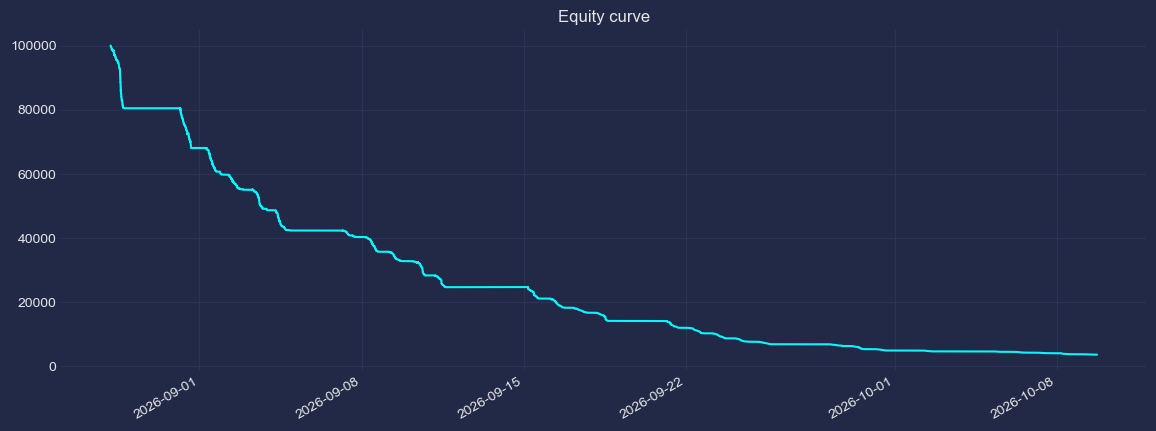

In [13]:
from src.backtesting.model_backtest import run_saved_model_backtest

# Строим X с DatetimeIndex из FINAL_DATASET и X_model
X_bt = X_model.copy()
X_bt.index = pd.to_datetime(FINAL_DATASET["bar_ts"], errors="coerce", utc=True)
X_bt = X_bt.sort_index()

# Запускаем бэктест — все параметры читаются из JSON автоматически
result = run_saved_model_backtest(
    model_path=r"C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\models\params\SMLT_catboost_20261010.cbm",
    X=X_bt,
    dollar_bars=bars,
    initial_capital=100_000,
)

display(result.trades.tail(5))
display(result.metrics)
result.equity.plot(figsize=(14, 5), title="Equity curve")
print(result.diagnostics)

## 7. Результат Optuna

Optuna минимизирует binary validation Log Loss на хронологическом validation-отрезке внутри development period. Финальный holdout отделён по времени и не участвует в подборе параметров. Лучшая конфигурация пересобирает датасет ещё раз и оценивается на holdout один раз.

**Важно:** оптимизация параметров разметки может менять состав и сложность целевой задачи. Низкий Log Loss не равен прибыльной стратегии; после этого нужен экономический backtest с исполнением на следующем баре, комиссиями и проскальзыванием.

In [27]:
# =============================================================================
# OPTUNA: REBUILD FULL 474-FEATURE DATASET PER TRIAL; BINARY DOWN/UP
# =============================================================================
import warnings
from pandas.errors import PerformanceWarning
warnings.filterwarnings("ignore", category=PerformanceWarning)
import optuna
from catboost import CatBoostClassifier
from sklearn.metrics import log_loss, accuracy_score, balanced_accuracy_score, f1_score
from src.data.labeling.cusum import cusum_filter
from src.data.labeling.triple_barrier import triple_barrier_labeling

optuna.logging.set_verbosity(optuna.logging.WARNING)

# All trials use only the already-loaded local `data` dict. No provider/API calls.
# Holdout cutoff comes from the baseline split above and is never used by objective().
HOLDOUT_CUTOFF = pd.Timestamp(HOLDOUT_START)
OPTUNA_TRIALS = 20
RANDOM_SEED = 63

def rebuild_full_features(dollar_threshold: int) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Rebuild Dollar Bars and all 474 causal features for one Optuna trial."""
    trial_bars = jfp.build_dollar_bars_from_trades(
        data["trades"], threshold=int(dollar_threshold)
    )
    if trial_bars is None or trial_bars.empty:
        raise RuntimeError("Dollar Bar builder returned an empty frame.")

    if "bar_ts" not in trial_bars.columns:
        if "close_time" not in trial_bars.columns:
            raise RuntimeError("Trial Dollar Bars have no bar_ts/close_time.")
        trial_bars["bar_ts"] = pd.to_datetime(trial_bars["close_time"], errors="coerce", utc=True)
    else:
        trial_bars["bar_ts"] = pd.to_datetime(trial_bars["bar_ts"], errors="coerce", utc=True)
    trial_bars = (
        trial_bars.dropna(subset=["bar_ts"]).sort_values("bar_ts")
        .drop_duplicates("bar_ts", keep="last").reset_index(drop=True)
    )

    trial_base = jfp._base(trial_bars.copy())
    if isinstance(trial_base, tuple):
        trial_base = trial_base[0]
    if not isinstance(trial_base, pd.DataFrame):
        raise TypeError("_base must return a DataFrame.")
    if "bar_ts" not in trial_base.columns:
        if "close_time" in trial_base.columns:
            trial_base = trial_base.rename(columns={"close_time": "bar_ts"})
        elif isinstance(trial_base.index, pd.DatetimeIndex):
            trial_base = trial_base.reset_index().rename(
                columns={trial_base.index.name or "index": "bar_ts"}
            )
        elif "ts" in trial_base.columns:
            trial_base = trial_base.rename(columns={"ts": "bar_ts"})
        else:
            raise RuntimeError("Cannot resolve timestamp in base features.")
    trial_base["bar_ts"] = pd.to_datetime(trial_base["bar_ts"], errors="coerce", utc=True)
    trial_base = (
        trial_base.dropna(subset=["bar_ts"]).sort_values("bar_ts")
        .drop_duplicates("bar_ts", keep="last").reset_index(drop=True)
    )
    trial_base_cols = [
        c for c in trial_base.columns
        if c != "bar_ts" and pd.api.types.is_numeric_dtype(trial_base[c])
    ]
    if len(trial_base_cols) != 73:
        raise RuntimeError(f"Expected 73 base features, got {len(trial_base_cols)}.")

    bars_sc = trial_bars.copy()
    if "ts" not in bars_sc.columns:
        bars_sc["ts"] = bars_sc["bar_ts"]
    if "CLOSE" not in bars_sc.columns:
        if "close" in bars_sc.columns:
            bars_sc["CLOSE"] = bars_sc["close"]
        else:
            raise RuntimeError("Trial bars have no CLOSE/close.")
    bars_sc["ts"] = pd.to_datetime(bars_sc["ts"], errors="coerce", utc=True)
    bars_sc = bars_sc.dropna(subset=["ts"]).sort_values("ts").reset_index(drop=True)

    sc_result = jfp._build_sc_features(data, bars_sc)
    if isinstance(sc_result, tuple):
        trial_frames = sc_result[0]
    else:
        trial_frames = sc_result
    if not isinstance(trial_frames, dict):
        raise TypeError("_build_sc_features must return a dict.")

    # Re-run source availability validation and causal attach for each trial.
    causal = trial_bars.copy()
    for source in ("tradestats", "obstats", "orderstats"):
        if data[source].empty:
            raise RuntimeError(f"Local source {source} is empty.")
        jfp._choose_availability(data[source].copy(), source)
        matches = [k for k in trial_frames if source.lower() in str(k).lower()]
        if source in trial_frames:
            feature_frame = trial_frames[source]
        elif len(matches) == 1:
            feature_frame = trial_frames[matches[0]]
        else:
            raise RuntimeError(f"Cannot resolve feature frame for {source}: {list(trial_frames)}")
        attached = jfp._attach_source(causal, feature_frame, data[source], source)
        if isinstance(attached, pd.DataFrame):
            causal = attached

    base_join = trial_base[["bar_ts"] + trial_base_cols].copy()
    base_join = base_join.rename(columns={c: f"base__{c}" for c in trial_base_cols})
    causal["bar_ts"] = pd.to_datetime(causal["bar_ts"], errors="coerce", utc=True)
    causal = causal.merge(base_join, on="bar_ts", how="left", validate="one_to_one")

    provenance_cols = [
        c for c in causal.columns
        if c.endswith("__event_ts") or c.endswith("__available_at")
    ]
    sc_prefixes = ("tradestats__", "obstats__", "orderstats__")
    sc_cols = [
        c for c in causal.columns
        if c.startswith(sc_prefixes)
        and c not in provenance_cols
        and pd.api.types.is_numeric_dtype(causal[c])
    ]
    base_cols = [c for c in causal.columns if c.startswith("base__")]
    trial_feature_cols = base_cols + sc_cols
    if len(trial_feature_cols) != EXPECTED_FEATURES:
        raise RuntimeError(
            f"Trial feature inventory mismatch: {len(trial_feature_cols)} != {EXPECTED_FEATURES}"
        )
    trial_dataset = (
        causal[["bar_ts"] + trial_feature_cols + provenance_cols]
        .sort_values("bar_ts").reset_index(drop=True)
    )
    # Check causal provenance on every rebuilt trial.
    for source in ("tradestats", "obstats", "orderstats"):
        av, ev = f"{source}__available_at", f"{source}__event_ts"
        if av in trial_dataset and (trial_dataset[av].notna() & (trial_dataset[av] > trial_dataset["bar_ts"])).any():
            raise RuntimeError(f"Availability leakage found in {source}.")
        if ev in trial_dataset and (trial_dataset[ev].notna() & (trial_dataset[ev] > trial_dataset["bar_ts"])).any():
            raise RuntimeError(f"Event-time leakage found in {source}.")

    trial_X = trial_dataset[trial_feature_cols].apply(pd.to_numeric, errors="coerce")
    trial_X = trial_X.replace([np.inf, -np.inf], np.nan)
    # Retain all feature columns; CatBoost can handle NaN natively.
    trial_dataset = trial_dataset.reset_index(drop=True)
    trial_X.index = pd.DatetimeIndex(trial_dataset["bar_ts"], name="bar_ts")
    return trial_bars, trial_X

def make_directional_labels(
    trial_bars: pd.DataFrame,
    trial_X: pd.DataFrame,
    cusum_threshold: float,
    tp_mult: float,
    sl_mult: float,
    vertical_horizon: int,
    target_window: int,
) -> tuple[pd.DataFrame, pd.Series, pd.DataFrame]:
    """Create Triple Barrier labels and align X/y at exact event timestamps."""
    b = trial_bars.copy()
    if "bar_ts" not in b.columns:
        b["bar_ts"] = pd.to_datetime(b["close_time"], errors="coerce", utc=True)
    rename = {
        "open": "OPEN", "high": "HIGH", "low": "LOW", "close": "CLOSE",
        "OPEN": "OPEN", "HIGH": "HIGH", "LOW": "LOW", "CLOSE": "CLOSE",
    }
    b = b.rename(columns=rename)
    missing = [c for c in ("HIGH", "LOW", "CLOSE") if c not in b.columns]
    if missing:
        raise RuntimeError(f"Missing OHLC columns: {missing}")
    b["bar_ts"] = pd.to_datetime(b["bar_ts"], errors="coerce", utc=True)
    b = (
        b.dropna(subset=["bar_ts", "HIGH", "LOW", "CLOSE"])
        .sort_values("bar_ts").drop_duplicates("bar_ts", keep="last")
        .set_index("bar_ts")
    )
    b.index.name = "bar_ts"
    events = cusum_filter(b["CLOSE"].astype(float), threshold=float(cusum_threshold))
    events = pd.DatetimeIndex(events)
    events = events[events.isin(b.index)].drop_duplicates().sort_values()
    if len(events) == 0:
        raise RuntimeError("CUSUM returned no events.")

    labs = triple_barrier_labeling(
        bars=b,
        events=events,
        pt_sl=(float(tp_mult), float(sl_mult)),
        vertical_barrier=int(vertical_horizon),
        target_window=int(target_window),
        target_method="ewm",
    )
    if labs is None or labs.empty or not {"label", "t1"}.issubset(labs.columns):
        raise RuntimeError("Triple Barrier returned no usable labels.")
    labs.index = pd.to_datetime(labs.index, errors="coerce", utc=True)
    labs = labs[~labs.index.isna()].sort_index()
    labs = labs[labs["label"].isin([-1, 0, 1])].copy()
    labs["label"] = labs["label"].astype(int)
    labs["t1"] = pd.to_datetime(labs["t1"], errors="coerce", utc=True)

    # Exact event-time alignment; no nearest-time or forward joins.
    X_evt = trial_X.reindex(labs.index)
    y_evt = labs["label"].reindex(X_evt.index)
    mask = y_evt.notna()
    X_evt, y_evt = X_evt.loc[mask], y_evt.loc[mask].astype(int)
    labs = labs.reindex(X_evt.index)

    # TIME is deliberately excluded from the learning target.
    keep = y_evt.isin([-1, 1])
    X_evt = X_evt.loc[keep].copy()
    y_evt = y_evt.loc[keep].copy().map({-1: 0, 1: 1}).astype(int)
    labs = labs.reindex(X_evt.index).copy()
    if len(X_evt) < 100 or y_evt.nunique() != 2:
        raise RuntimeError("Too few directional events or only one direction.")
    return X_evt, y_evt, labs

def purged_dev_validation(X_evt, y_evt, labs, holdout_cutoff):
    # Entire later holdout is excluded from Optuna objective.
    dev_mask = X_evt.index < holdout_cutoff
    X_dev = X_evt.loc[dev_mask]
    y_dev = y_evt.loc[dev_mask]
    lab_dev = labs.reindex(X_dev.index)
    if len(X_dev) < 200 or y_dev.nunique() != 2:
        raise RuntimeError("Insufficient development events before holdout cutoff.")

    split = int(len(X_dev) * 0.80)
    val_start = X_dev.index[split]
    tr_candidates = X_dev.index[:split]
    val_idx = X_dev.index[split:]
    end_times = pd.to_datetime(lab_dev.reindex(tr_candidates)["t1"], errors="coerce", utc=True)
    keep = end_times.notna() & (end_times < val_start)
    tr_idx = tr_candidates[keep.to_numpy()]
    if len(tr_idx) < 100 or len(val_idx) < 50:
        raise RuntimeError("Too few train/validation events after purging.")
    if y_dev.loc[tr_idx].nunique() != 2 or y_dev.loc[val_idx].nunique() != 2:
        raise RuntimeError("Train or validation contains only one directional class.")
    return X_dev.loc[tr_idx], y_dev.loc[tr_idx], X_dev.loc[val_idx], y_dev.loc[val_idx]

def objective(trial):
    # Dataset/label parameters: every trial rebuilds the entire pipeline.
    dollar_threshold = trial.suggest_int("DOLLAR_THRESHOLD", 5_000_000, 25_000_000, step=1_000_000)
    cusum_threshold = trial.suggest_float("CUSUM_THRESHOLD", 0.0002, 0.005, log=True)
    tp_mult = trial.suggest_float("TP_MULTIPLIER", 0.3, 2.5)
    sl_mult = trial.suggest_float("SL_MULTIPLIER", 0.3, 2.5)
    vertical_horizon = trial.suggest_int("VERTICAL_HORIZON", 10, 100, step=5)
    target_window = trial.suggest_int("TARGET_WINDOW", 20, 100, step=5)

    trial_bars, trial_X = rebuild_full_features(dollar_threshold)
    X_evt, y_evt, labs = make_directional_labels(
        trial_bars, trial_X, cusum_threshold, tp_mult, sl_mult,
        vertical_horizon, target_window,
    )
    X_tr, y_tr, X_val, y_val = purged_dev_validation(
        X_evt, y_evt, labs, HOLDOUT_CUTOFF
    )

    model = CatBoostClassifier(
        iterations=trial.suggest_int("iterations", 300, 800, step=100),
        depth=trial.suggest_int("depth", 4, 9),
        learning_rate=trial.suggest_float("learning_rate", 0.015, 0.15, log=True),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1.0, 15.0, log=True),
        loss_function="Logloss",
        eval_metric="Logloss",
        random_seed=RANDOM_SEED,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1,
    )
    model.fit(X_tr, y_tr, eval_set=(X_val, y_val), early_stopping_rounds=80, verbose=False)
    prob_up = model.predict_proba(X_val)[:, 1]
    
    # === НОВАЯ ЦЕЛЕВАЯ ФУНКЦИЯ: total_return от бэктеста ===
    signals = pd.Series(
        np.where(prob_up >= 0.5, 1, -1),
        index=X_val.index,
        name="signal"
    )
    
    val_labs = labs.reindex(X_val.index)[["upper", "lower", "t1"]].dropna()
    signals = signals.loc[val_labs.index]
    
    from src.backtesting.backtest_engine import backtest, BacktestConfig
    
    config = BacktestConfig(barrier_mode="event_labels", commission=0.0006, slippage=0.0001, entry_cutoff_hour=22, forced_close_hour=23, session_timezone="Europe/Moscow",)
    
    result = backtest(bars=trial_bars, signals=signals, config=config, event_labels=val_labs, initial_capital=100_000,)
    
    total_return = result.metrics.get("total_return", 0)
    
    trial.set_user_attr("train_rows", len(X_tr))
    trial.set_user_attr("validation_rows", len(X_val))
    trial.set_user_attr("directional_rows_before_holdout", int((X_evt.index < HOLDOUT_CUTOFF).sum()))
    trial.set_user_attr("total_return", total_return)
    
    return float(total_return)

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED), study_name=f"JERICHON_{TICKER}_full474_binary",)

print(f"Starting Optuna: {OPTUNA_TRIALS} trials; holdout begins at {HOLDOUT_CUTOFF}")
study.optimize(objective, n_trials=OPTUNA_TRIALS, gc_after_trial=True, show_progress_bar=True)

print("\nBEST OPTUNA RESULT")
print("Total Return: ", round(study.best_value, 6))
display(pd.DataFrame([study.best_params]).T.rename(columns={0: "best_value"}))
display(pd.DataFrame([study.best_params]).T.rename(columns={0: "best_value"}))

# Rebuild the best configuration and evaluate the untouched holdout once.
bp = study.best_params
best_bars, best_X = rebuild_full_features(bp["DOLLAR_THRESHOLD"])
best_X_evt, best_y_evt, best_labs = make_directional_labels(
    best_bars, best_X,
    bp["CUSUM_THRESHOLD"], bp["TP_MULTIPLIER"], bp["SL_MULTIPLIER"],
    bp["VERTICAL_HORIZON"], bp["TARGET_WINDOW"],)

dev_mask = best_X_evt.index < HOLDOUT_CUTOFF
hold_mask = best_X_evt.index >= HOLDOUT_CUTOFF
X_dev_all = best_X_evt.loc[dev_mask]
y_dev_all = best_y_evt.loc[dev_mask]
labs_dev_all = best_labs.reindex(X_dev_all.index)
X_holdout = best_X_evt.loc[hold_mask]
y_holdout = best_y_evt.loc[hold_mask]
if len(X_dev_all) < 100 or len(X_holdout) < 50 or y_holdout.nunique() != 2:
    raise RuntimeError(
        "Best-parameter holdout is too small or has only one class; "
        "do not interpret a one-class holdout score."
    )
hold_start = X_holdout.index.min()
ends = pd.to_datetime(labs_dev_all["t1"], errors="coerce", utc=True)
train_keep = ends.notna() & (ends < hold_start)
X_final_train = X_dev_all.loc[train_keep.to_numpy()]
y_final_train = y_dev_all.loc[train_keep.to_numpy()]
if y_final_train.nunique() != 2:
    raise RuntimeError("Final purged development train has only one class.")

final_model = CatBoostClassifier(
    iterations=bp["iterations"],
    depth=bp["depth"],
    learning_rate=bp["learning_rate"],
    l2_leaf_reg=bp["l2_leaf_reg"],
    loss_function="Logloss",
    eval_metric="Logloss",
    random_seed=RANDOM_SEED,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1,
)
final_model.fit(X_final_train, y_final_train, verbose=False)
p_up = final_model.predict_proba(X_holdout)[:, 1]
pred_holdout = (p_up >= 0.5).astype(int)

print("\nFINAL UNTOUCHED HOLDOUT — DOWN=0, UP=1")
print(f"Features: {X_final_train.shape[1]} | train={len(X_final_train):,} | holdout={len(X_holdout):,}")
print(f"Log Loss         : {log_loss(y_holdout, np.column_stack([1-p_up, p_up]), labels=[0, 1]):.5f}")
print(f"Accuracy         : {accuracy_score(y_holdout, pred_holdout):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_holdout, pred_holdout):.4f}")
print(f"Macro F1         : {f1_score(y_holdout, pred_holdout, average='macro'):.4f}")
print("\nHoldout classes:")
print(y_holdout.value_counts().sort_index().rename(index={0: "DOWN", 1: "UP"}))


Starting Optuna: 20 trials; holdout begins at 2026-09-23 14:05:59+00:00


  0%|          | 0/20 [00:00<?, ?it/s]


BEST OPTUNA RESULT
Total Return:  -0.077355


,best_value
DOLLAR_THRESHOLD,2.400000e+07
CUSUM_THRESHOLD,3.529349e-03
TP_MULTIPLIER,1.800135e+00
SL_MULTIPLIER,2.258772e+00
VERTICAL_HORIZON,2.500000e+01
TARGET_WINDOW,8.500000e+01
iterations,3.000000e+02
depth,9.000000e+00
learning_rate,7.001573e-02
l2_leaf_reg,7.461647e+00


,best_value
DOLLAR_THRESHOLD,2.400000e+07
CUSUM_THRESHOLD,3.529349e-03
TP_MULTIPLIER,1.800135e+00
SL_MULTIPLIER,2.258772e+00
VERTICAL_HORIZON,2.500000e+01
TARGET_WINDOW,8.500000e+01
iterations,3.000000e+02
depth,9.000000e+00
learning_rate,7.001573e-02
l2_leaf_reg,7.461647e+00



FINAL UNTOUCHED HOLDOUT — DOWN=0, UP=1
Features: 474 | train=1,250 | holdout=438
Log Loss         : 0.74245
Accuracy         : 0.5571
Balanced Accuracy: 0.5492
Macro F1         : 0.5128

Holdout classes:
label
DOWN    213
UP      225
Name: count, dtype: int64


In [45]:

from pathlib import Path
import json, datetime, sklearn, catboost, optuna

out = Path(r"C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\models\params")
out.mkdir(parents=True, exist_ok=True)
name = f"{TICKER}_catboost_{datetime.datetime.now():%Y%m%d}"
model_path, config_path = out/f"{name}.cbm", out/f"{name}.json"

final_model.save_model(str(model_path))
config = {
    "ticker": TICKER,
    "model_file": model_path.name,
    "model_type": "CatBoostClassifier",
    "task": "binary_direction_prediction",
    "classes": {"0": "DOWN", "1": "UP"},
    "decision_threshold": 0.5,
    "feature_count": len(X_final_train.columns),
    "feature_names_ordered": list(X_final_train.columns),
    "optuna_best_params": study.best_params,
    "optuna_best_validation_logloss": study.best_value,
    "optuna_trials": OPTUNA_TRIALS,
    "optuna_history": study.trials_dataframe().to_dict(orient="records"),
    "label_config": {
        "CUSUM_THRESHOLD": bp["CUSUM_THRESHOLD"],
        "TP_MULTIPLIER": bp["TP_MULTIPLIER"],
        "SL_MULTIPLIER": bp["SL_MULTIPLIER"],
        "VERTICAL_HORIZON": bp["VERTICAL_HORIZON"],
        "TARGET_WINDOW": bp["TARGET_WINDOW"],
        "mapping": {"DOWN": 0, "UP": 1, "TIME": "excluded"}
    },
    "data_config": {
        "DOLLAR_THRESHOLD": bp["DOLLAR_THRESHOLD"],
        "feature_set": "full474",
        "training_rows": len(X_final_train),
        "training_start": str(X_final_train.index.min()),
        "training_end": str(X_final_train.index.max()),
        "holdout_start": str(X_holdout.index.min()),
        "holdout_rows": len(X_holdout),
        "purged_before_holdout": True
    },
    "versions": {
        "catboost": catboost.__version__,
        "optuna": optuna.__version__,
        "sklearn": sklearn.__version__
    }
}
config_path.write_text(json.dumps(config, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print(f"Модель: {model_path}\nКонфигурация и история Optuna: {config_path}")

Модель: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\models\params\GAZP_catboost_20261010.cbm
Конфигурация и история Optuna: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\models\params\GAZP_catboost_20261010.json
